In [3]:
import pandas as pd

df = pd.read_csv("house_prices.csv")

In [4]:
print(df.head())

   House_Size_sq_ft  Price_Lakhs
0               500           15
1               650           19
2               800           24
3               950           28
4              1100           33


In [5]:
print(df.tail())

    House_Size_sq_ft  Price_Lakhs
10              2000           62
11              2200           67
12              2400           73
13              2600           78
14              2800           85


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   House_Size_sq_ft  15 non-null     int64
 1   Price_Lakhs       15 non-null     int64
dtypes: int64(2)
memory usage: 372.0 bytes
None


In [7]:
print(df.duplicated().sum())
print(df.isnull().sum())

0
House_Size_sq_ft    0
Price_Lakhs         0
dtype: int64


In [ ]:
print(df.describe())

       House_Size_sq_ft  Price_Lakhs
count         15.000000    15.000000
mean        1583.333333    47.866667
std          720.036375    22.057932
min          500.000000    15.000000
25%         1025.000000    30.500000
50%         1550.000000    46.000000
75%         2100.000000    64.500000
max         2800.000000    85.000000


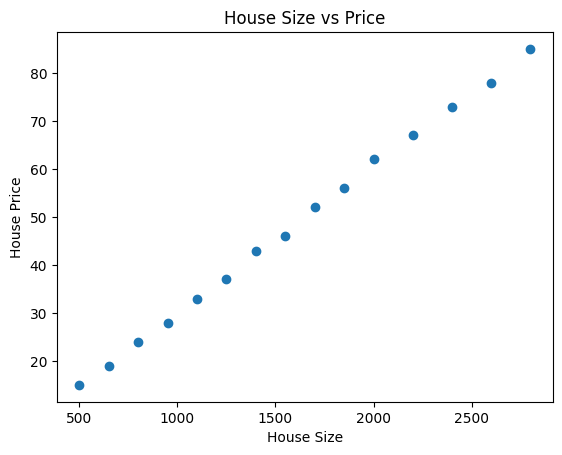

In [9]:
import matplotlib.pyplot as plt

plt.scatter(df['House_Size_sq_ft'],df['Price_Lakhs'])
plt.xlabel("House Size")
plt.ylabel("House Price")
plt.title("House Size vs Price")
plt.show()

identify feature and target


In [10]:
df.columns

Index(['House_Size_sq_ft', 'Price_Lakhs'], dtype='object')

In [11]:
X = df[['House_Size_sq_ft']]
y = df['Price_Lakhs']

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y, 
                                                    random_state=42,
                                                    test_size=0.2)

In [13]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.03]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['House_Size_sq_ft']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.7182
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [14]:
y_pred = model.predict(X_test)
print(y_pred)

[55.99763173 66.7276495  14.61042037]


In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np

print("MAE",mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
print("RMSE",rmse)
print("R2 Score",r2_score(y_test,y_pred))

MAE 0.22143280047365602
MSE 0.07531756522982952
RMSE 0.27444045844195336
R2 Score 1.0


In [16]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "predicted": y_pred
})
print(comparison)

    Actual  predicted
9       56  55.997632
11      67  66.727649
0       15  14.610420


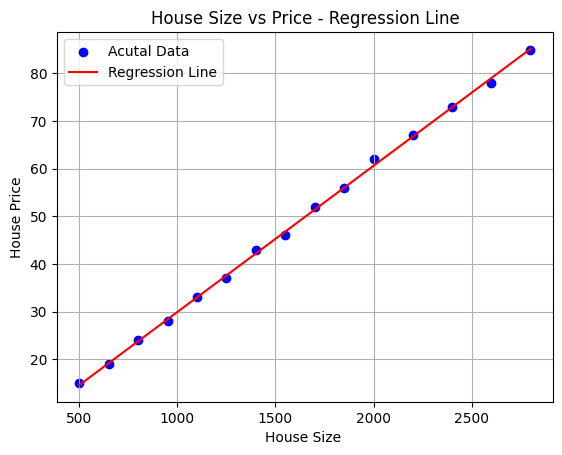

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(X, y, color = "blue", label="Acutal Prices")

y_line = model.predict(X)

plt.plot(
    X['House_Size_sq_ft'],
    y_line,
    color = "Red",
    label ="Regression Line"
)

plt.title("House Size vs Price - Regression Line")
plt.xlabel("House Size (sq ft)")
plt.ylabel("House Price(Lakhs)")

plt.legend()
plt.grid(True)
plt.show()

predicting for new data

In [28]:
new_data = pd.DataFrame({
    'House_Size_sq_ft': [1500]

})
prediction = model.predict(new_data)
print(prediction)

[45.26761397]


\[
Price = (Coefficient * 1500) + Intercept
\]

\[
Price Change = Coefficient * 100
\]

Positive coefficient: larger houses have higher predicted prices.



Negative coefficient: larger houses have lower predicted prices.



Zero coefficient: house size does not change the prediction.

The intercept represents the predicted price when house size is zero.

In [32]:
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

print("Smallest house:", X.min().values[0])
print("Largest house:", X.max().values[0])

Coefficient: 0.030657193605683836
Intercept: -0.7181764357608031
Smallest house: 500
Largest house: 2800


In [33]:
print("100 sqft price change",model.coef_ * 100)

100 sqft price change [3.06571936]


House price changes 3 lakhs in 100 sqft change
positive relationship beacause coefficient is positive


Negative intercept means that when house size is zero, the model predicts:

-₹0.718 lakhs (approximately -₹71,818).

This doesn't make practical sense for a real house.

However, the intercept is a mathematical starting point for the regression line. It doesn't mean that actual houses have negative prices.

Your model has learned the relationship from houses between 500 and 2,800 sq ft. It has no direct evidence that the same linear relationship continues up to 5,000 sq ft.

Therefore, I would not trust that prediction without more data.

Coefficient – How much the prediction changes when the input increases by one unit.



Intercept – Predicted target value when all input features are zero.



Extrapolation – Predicting beyond the range of the training data.